### CodeBleu 
The environment here is python 3.11.15 to use the CodeBleu method. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

# import iohclustering

In [2]:
FIDS = list(range(1, 11))
INSTANCES = [1]
K_VALUES = [2, 3, 5, 10]

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Classfied algorithms convergence behaviour

In [3]:
import pandas as pd
from iohblade.loggers import ExperimentLogger
from pathlib import Path
import glob 

BASE_DIR = Path.cwd().parent.parent  
results_path = BASE_DIR / "results"

logger = ExperimentLogger(name=str(results_path / "mutation_5_runs_elitism_off_16"), read=True)

# registered_exp = logger.add_read_dir('results/Results_compare_KMeans_changed_Task_Prompt_to_be_Diverse(only one type of Alg)')
# df = logger.get_methods_problems()
# # print(df)
# df = logger.get_data()
# print(df[["method_name", "problem_name", "log_dir", "seed"]])
df = logger.get_problem_data("CLUSTERING")
print(type(df))


c:\Users\Anna Michelle\.conda\envs\codebleu311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<class 'pandas.core.frame.DataFrame'>


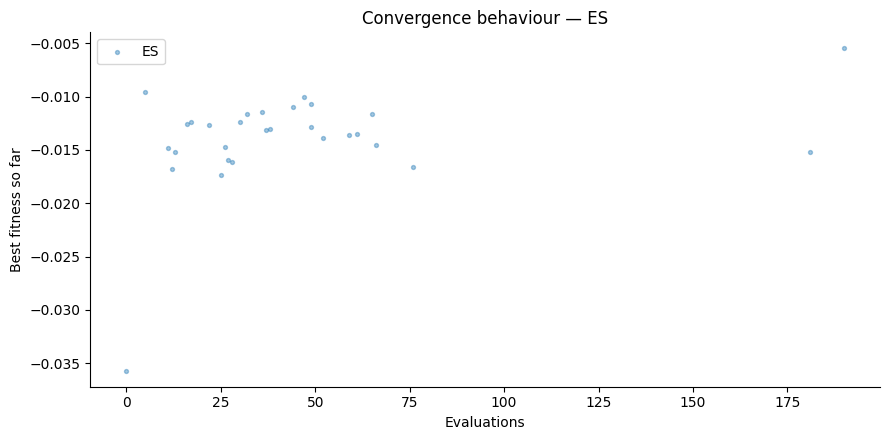

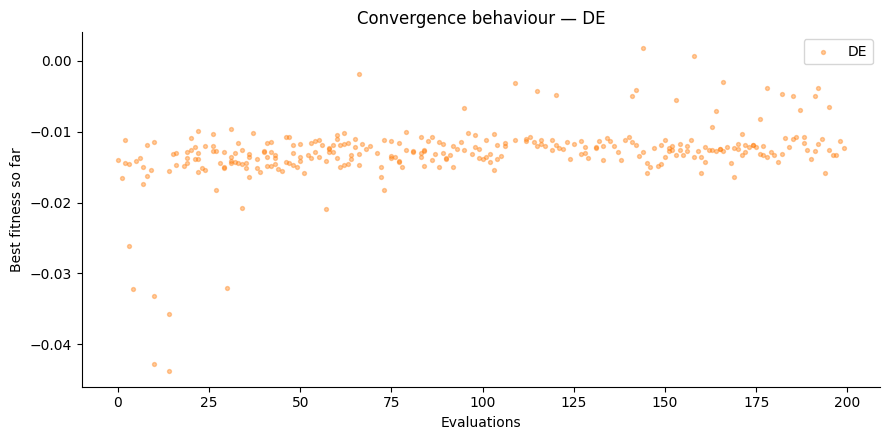

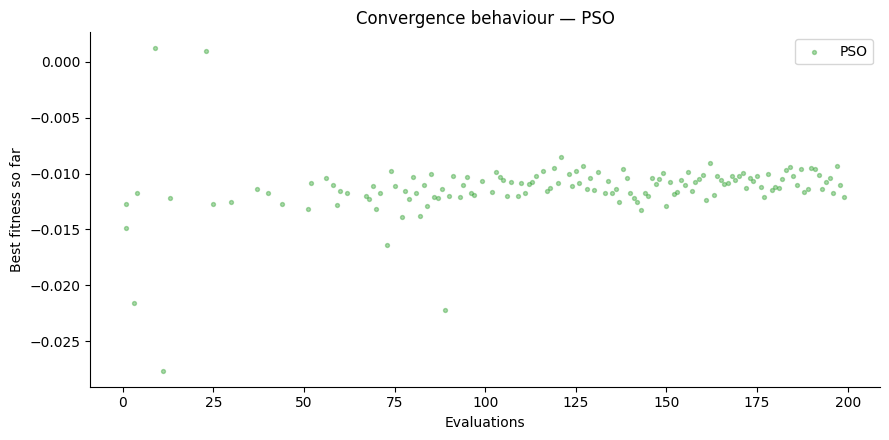

No data for Other, skipping


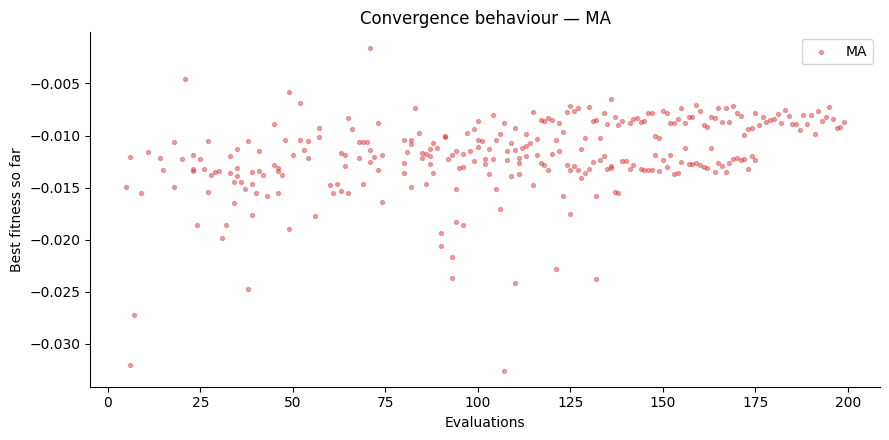

No data for SA, skipping


In [4]:
import numpy as np
import pandas as pd

df = logger.get_problem_data("CLUSTERING")

df["best_so_far"] = df.groupby(["name", "id"])["fitness"].cummax()

import matplotlib.pyplot as plt


def classify_algorithm(name: str, description: str = None) -> str:
    if pd.isna(name):
        return "Other"

    n = str(name).strip().upper()
    desc = str(description).strip().upper() if description and not pd.isna(description) else ""

    explicit_map = {
        "HYBRIDDELOCALSEARCH": "ES",
        "CLUSTERINGHYBRIDOPTIMIZER": "DE",
        "CHAOSENHANCEDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVECHAOTICCLUSTERINGOPTIMIZER": "DE",
        "ENTROPYDRIVENCLUSTERINGOPTIMIZER": "DE",
        "CHAOTICHYBRIDCLUSTERINGOPTIMIZER": "DE",
        "HYBRIDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVEESCLUSTERING": "ES",
        "ADAPTIVEPSOCLUSTERING": "PSO",
        "ADAPTIVEMULTISWARMCLUSTERING": "PSO",
        "ADAPTIVECLUSTERINGEA": "ES",
        "ECA": "ES",
    }

    if n in explicit_map:
        return explicit_map[n]

    # Simulated Annealing — check name first, then description
    if "SIMULATED" in n or "ANNEALING" in n or "SA" == n:
        return "SA"
    if "SIMULATED ANNEALING" in desc or "ANNEALING" in desc:
        return "SA"

    if "PSO" in n or "SWARM" in n:
        return "PSO"

    if "UMDA" in n or "EDA" in n:
        return "EDA"

    # DE + Memetic combos: name contains DE signals AND local search signals
    de_signal = "DE" in n or "DIFFERENTIAL" in n
    local_search_signal = (
        "MEMETIC" in n or "LOCAL" in n or "LOCAL SEARCH" in desc
        or "LOCAL-SEARCH" in desc or "MEMETIC" in desc
    )

    if de_signal and local_search_signal:
        return "DE"

    if de_signal:
        return "DE"

    # Pure memetic: name says memetic, or description mentions local search
    if "MEMETIC" in n or local_search_signal:
        return "MA"

    if "EA" in n or "EVOLUTIONARY" in n or "ES" in n or "ECA" in n or "ADAPTIVECLUSTERING" in n:
        return "ES"

    return "ES"


# Pass description column if available
if "description" in df.columns:
    df["algorithm_category"] = df.apply(
        lambda r: classify_algorithm(r["name"], r.get("description")), axis=1
    )
else:
    df["algorithm_category"] = df["name"].apply(classify_algorithm)

categories = ["ES", "DE", "PSO", "MA"]
df_plot = df[df["algorithm_category"].isin(categories)].copy()

df_plot = df_plot[np.isfinite(df_plot["best_so_far"])]
df_plot = df_plot[~np.isclose(df_plot["best_so_far"], -1e9, atol=1e6)]
df_plot = df_plot[df_plot["best_so_far"] >= -1]

color_map = {
    "ES": "tab:blue",
    "DE":  "tab:orange",
    "PSO":   "tab:green",
    "MA": "tab:red",
}

for alg in ["ES", "DE", "PSO", "Other", "MA", "SA"]:
    subset = df_plot[df_plot["algorithm_category"] == alg]
    if subset.empty:
        print(f"No data for {alg}, skipping")
        continue

    plt.figure(figsize=(9, 4.5))
    plt.scatter(
        subset["_id"],
        subset["best_so_far"],
        label=alg,
        color=color_map.get(alg, "tab:gray"),
        s=8,
        alpha=0.4,
    )

    plt.xlabel("Evaluations")
    plt.ylabel("Best fitness so far")
    plt.title(f"Convergence behaviour — {alg}")
    plt.legend()
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

In [5]:
# All unique algorithm names and their counts
algo_counts = df["name"].value_counts().reset_index()
algo_counts.columns = ["name", "count"]

# Add the category each name maps to
if "description" in df.columns:
    algo_counts["category"] = algo_counts["name"].apply(
        lambda n: classify_algorithm(n, df.loc[df["name"] == n, "description"].iloc[0])
    )
else:
    algo_counts["category"] = algo_counts["name"].apply(classify_algorithm)

print(f"Total unique algorithm names: {len(algo_counts)}")
print(f"Total rows: {len(df)}\n")
print(algo_counts.to_string(index=False))

Total unique algorithm names: 47
Total rows: 976

                                     name  count category
              AdaptiveClusteringOptimizer    380       ES
                ClusteringHybridOptimizer    135       DE
              AdaptiveHybridPSOClustering    129      PSO
         ChaosEnhancedClusteringOptimizer     81       DE
                     AdaptiveDEClustering     48       DE
DiversityGuidedChaoticClusteringOptimizer     23       DE
                               AdaptiveDE     22       DE
       AdaptiveChaoticClusteringOptimizer     22       DE
         EntropyDrivenClusteringOptimizer     15       DE
         ChaoticHybridClusteringOptimizer     14       DE
                      HybridPSOClustering     14      PSO
     DiversityAdaptiveClusteringOptimizer     13       MA
                HybridClusteringOptimizer     11       DE
                              AdaptivePSO      8      PSO
         EntropyGuidedClusteringOptimizer      7       DE
            DiversityA

Code bleu again 

In [6]:
import pandas as pd
from iohblade.loggers import ExperimentLogger

# confirm logger loading works as expected 
logger = ExperimentLogger(name=str(results_path / "mutation_5_runs_elitism_off_16"), read=True)

df = logger.get_problem_data("CLUSTERING")
print(type(df))


<class 'pandas.core.frame.DataFrame'>


In [7]:
import pandas as pd
from iohblade.loggers import ExperimentLogger

EXPS_TO_COMBINE = {
    "E3: Mutation w/o Elitism":   str(results_path / "mutation_5_runs_elitism_off_16"),
    "E5: Mutation + Elitism":    str(results_path / "mutation_5_runs_elitism_on"),
    "E4: Warm Start w/o Elitism": str(results_path / "warm_start_5_runs_elitism_off_16_child"),
    "E6: Warm Start + Elitism":   str(results_path / "warm_start_5_runs"),
}

dfs = []
for exp_label, result_dir in EXPS_TO_COMBINE.items():
    logger = ExperimentLogger(name=result_dir, read=True)
    exp_df = logger.get_problem_data("CLUSTERING")
    exp_df["source_experiment"] = exp_label
    dfs.append(exp_df)
    print(f"{exp_label}: {len(exp_df)} rows")

df = pd.concat(dfs, ignore_index=True)
print(f"\nCombined df: {len(df)} rows")
print(df["source_experiment"].value_counts())

E3: Mutation w/o Elitism: 976 rows
E5: Mutation + Elitism: 1000 rows
E4: Warm Start w/o Elitism: 1000 rows
E6: Warm Start + Elitism: 1000 rows

Combined df: 3976 rows
source_experiment
E5: Mutation + Elitism        1000
E4: Warm Start w/o Elitism    1000
E6: Warm Start + Elitism      1000
E3: Mutation w/o Elitism       976
Name: count, dtype: int64


In [8]:
# classification map 
def classify_algorithm(name: str, description: str = None) -> str:
    if pd.isna(name):
        return "Other"

    n = str(name).strip().upper()
    desc = str(description).strip().upper() if description and not pd.isna(description) else ""

    explicit_map = {
        "HYBRIDDELOCALSEARCH": "ES",
        "CLUSTERINGHYBRIDOPTIMIZER": "DE",
        "CHAOSENHANCEDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVECHAOTICCLUSTERINGOPTIMIZER": "DE",
        "ENTROPYDRIVENCLUSTERINGOPTIMIZER": "DE",
        "CHAOTICHYBRIDCLUSTERINGOPTIMIZER": "DE",
        "HYBRIDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVEESCLUSTERING": "ES",
        "ADAPTIVEPSOCLUSTERING": "PSO",
        "ADAPTIVEMULTISWARMCLUSTERING": "PSO",
        "ADAPTIVECLUSTERINGEA": "ES",
        "ECA": "ES",
    }

    if n in explicit_map:
        return explicit_map[n]

    # SA check name first, then description
    if "SIMULATED" in n or "ANNEALING" in n or "SA" == n:
        return "SA"
    if "SIMULATED ANNEALING" in desc or "ANNEALING" in desc:
        return "SA"

    if "PSO" in n or "SWARM" in n:
        return "PSO"

    if "UMDA" in n or "EDA" in n:
        return "EDA"

    # name contains DE signals AND local search signals
    de_signal = "DE" in n or "DIFFERENTIAL" in n
    local_search_signal = (
        "MEMETIC" in n or "LOCAL" in n or "LOCAL SEARCH" in desc
        or "LOCAL-SEARCH" in desc or "MEMETIC" in desc
    )
    # chose to classify DE + local search as DE
    if de_signal and local_search_signal:
        return "DE"

    if de_signal:
        return "DE"

    # pure memetic: name says memetic, or description mentions local search
    if "MEMETIC" in n or local_search_signal:
        return "MA"

    if "EA" in n or "EVOLUTIONARY" in n or "ES" in n or "ECA" in n or "ADAPTIVECLUSTERING" in n:
        return "ES"

    return "ES"


# pass description column if available
if "description" in df.columns:
    df["algorithm_category"] = df.apply(
        lambda r: classify_algorithm(r["name"], r.get("description")), axis=1
    )
else:
    df["algorithm_category"] = df["name"].apply(classify_algorithm)

categories = ["ES", "DE", "PSO", "MA", "SA"]
df_plot = df[df["algorithm_category"].isin(categories)].copy()

In [9]:
from codebleu import calc_codebleu
from itertools import combinations
from tqdm import tqdm

def compute_codebleu(code_a: str, code_b: str) -> float:
    if not isinstance(code_a, str) or not isinstance(code_b, str):
        return np.nan
    if not code_a.strip() or not code_b.strip():
        return np.nan
    try:
        result = calc_codebleu(
            references=[code_a],
            predictions=[code_b],
            lang="python",
            weights=(0.33, 0.33, 0.34, 0.0),  # ngram, weighted_ngram, syntax, no dataflow
        )
        return result["codebleu"]
    except Exception as e:
        return np.nan
    
# One row per unique algorithm: take the first code/description/best fitness
algo_df = (
    df_plot[df_plot["code"].notna() & df_plot["algorithm_category"].notna()]
    .groupby("name")
    .agg(
        code=("code", "first"),
        description=("description", "first") if "description" in df_plot.columns else ("code", "first"),
        category=("algorithm_category", "first"),
        best_fitness=("fitness", "max"),   # best/highest fitness seen
        mean_fitness=("fitness", "mean"),
    )
    .reset_index()
)

print(f"Unique algorithms for CodeBLEU: {len(algo_df)}")
print(algo_df["category"].value_counts())

# store results as a dict keyed by (name_i, name_j) - for pairwise comparison
names = algo_df["name"].tolist()
codes = algo_df["code"].tolist()
n = len(names)

pairwise = {}

for i, j in tqdm(combinations(range(n), 2), total=n*(n-1)//2, desc="CodeBLEU"):
    score = compute_codebleu(codes[i], codes[j])
    pairwise[(names[i], names[j])] = score
    pairwise[(names[j], names[i])] = score

# make the values that are the same have a similarity score of 1
for name in names:
    pairwise[(name, name)] = 1.0

# make the matrix of categories

cat_matrix = pd.DataFrame(index=categories, columns=categories, dtype=float)

for cat_i in categories:
    names_i = algo_df.loc[algo_df["category"] == cat_i, "name"].tolist()
    for cat_j in categories:
        names_j = algo_df.loc[algo_df["category"] == cat_j, "name"].tolist()

        scores = []
        for ni in names_i:
            for nj in names_j:
                if ni != nj:  # exclude self when same category
                    s = pairwise.get((ni, nj), np.nan)
                    if not np.isnan(s):
                        scores.append(s)

        cat_matrix.loc[cat_i, cat_j] = np.mean(scores) if scores else np.nan

print("\nCategory-pair CodeBLEU matrix:")
print(cat_matrix.to_string())

# mean CodeBLEU of each algorithm vs all others in its category
algo_df["mean_codebleu_within_cat"] = algo_df.apply(
    lambda r: np.nanmean([
        pairwise.get((r["name"], other), np.nan)
        for other in algo_df.loc[algo_df["category"] == r["category"], "name"]
        if other != r["name"]
    ]),
    axis=1
)

print("\n── Per-algorithm CodeBLEU vs fitness ──")
print(
    algo_df[["name", "category", "best_fitness", "mean_fitness", "mean_codebleu_within_cat"]]
    .sort_values(["category", "mean_codebleu_within_cat"], ascending=[True, False])
    .to_string(index=False)
)

Unique algorithms for CodeBLEU: 147
category
MA     59
DE     54
PSO    17
ES     16
SA      1
Name: count, dtype: int64


CodeBLEU: 100%|██████████| 10731/10731 [17:37<00:00, 10.15it/s]


Category-pair CodeBLEU matrix:
           ES        DE       PSO        MA        SA
ES   0.306248  0.296904  0.293255  0.299399  0.261327
DE   0.296904  0.315793  0.284304  0.296014  0.267265
PSO  0.293255  0.284304  0.324380  0.282422  0.239962
MA   0.299399  0.296014  0.282422  0.300326  0.272848
SA   0.261327  0.267265  0.239962  0.272848       NaN

── Per-algorithm CodeBLEU vs fitness ──
                                       name category  best_fitness  mean_fitness  mean_codebleu_within_cat
                                 AdaptiveDE       DE -1.010515e-02          -inf                  0.372378
                  AdaptiveDEWithLocalSearch       DE -1.251632e-02          -inf                  0.350023
  DiversityGuidedChaoticClusteringOptimizer       DE -1.025008e-02          -inf                  0.348804
           ChaoticHybridClusteringOptimizer       DE -1.030487e-02          -inf                  0.348138
                   AdaptiveChaosDEOptimizer       DE -1.041000e-02 -


C:\Users\Anna Michelle\AppData\Local\Temp\ipykernel_1656\2434539182.py:78: RuntimeWarning: Mean of empty slice
  lambda r: np.nanmean([


In [10]:
# ensure clean df first
import numpy as np

FAILURE_SENTINEL = -1e6

print(f"Rows before cleaning: {len(df_plot)}")
bad_fitness = (
    (df_plot["fitness"] <= FAILURE_SENTINEL) |
    (df_plot["fitness"] == -np.inf) |
    df_plot["fitness"].isna()
)
print(f"Rows removed (failed fitness): {bad_fitness.sum()}")
df_clean = df_plot[~bad_fitness].reset_index(drop=True)
print(f"Rows after cleaning: {len(df_clean)}\n")

# build algo_df
algo_df = (
    df_clean[df_clean["code"].notna() & df_clean["algorithm_category"].notna()]
    .groupby(["name", "code"], sort=False)
    .agg(
        description=("description", "first") if "description" in df_clean.columns else ("code", "first"),
        category=("algorithm_category", "first"),
        best_fitness=("fitness", "max"),
        mean_fitness=("fitness", "mean"),
        n_runs=("fitness", "count"),       
    )
    .reset_index()
)

# unique version id for readability
algo_df["version_id"] = (
    algo_df["name"] + "_v" +
    algo_df.groupby("name").cumcount().add(1).astype(str)
)

failed_mask = algo_df["best_fitness"] <= FAILURE_SENTINEL
print(f"Versions excluded after cleaning: {failed_mask.sum()}")
algo_df = algo_df[~failed_mask].reset_index(drop=True)

print(f"Unique algorithm versions for CodeBLEU: {len(algo_df)}")
print(f"Unique algorithm names: {algo_df['name'].nunique()}")
print(algo_df["category"].value_counts())

# lookups keyed by version_id 
fitness_lookup  = algo_df.set_index("version_id")["best_fitness"].to_dict()
category_lookup = algo_df.set_index("version_id")["category"].to_dict()
name_lookup     = algo_df.set_index("version_id")["name"].to_dict()
names_all       = algo_df["version_id"].tolist()
codes_all       = algo_df["code"].tolist()

def safe_fitness(version_id):
    v = fitness_lookup.get(version_id, np.nan)
    if v is None or v <= FAILURE_SENTINEL:
        return np.nan
    return float(v)

# Verify
bad_in_lookup = {k: v for k, v in fitness_lookup.items() if v <= FAILURE_SENTINEL}
print(f"\nSentinel values still in fitness_lookup: {len(bad_in_lookup)}")

Rows before cleaning: 3959
Rows removed (failed fitness): 640
Rows after cleaning: 3319

Versions excluded after cleaning: 0
Unique algorithm versions for CodeBLEU: 1629
Unique algorithm names: 104
category
MA     550
DE     486
PSO    318
ES     256
SA      19
Name: count, dtype: int64

Sentinel values still in fitness_lookup: 0


Rows before cleaning: 3959
Rows removed (failed fitness): 640
Categories with >= 50 runs: ['DE', 'ES', 'MA', 'PSO']
Dropped categories: ['SA']

Total unique (name, code) versions: 1610
category
MA     550
DE     486
PSO    318
ES     256
Name: count, dtype: int64

Strategy A (best+worst+median): 208 versions
category
DE     89
MA     61
ES     30
PSO    28
Name: count, dtype: int64


C:\Users\Anna Michelle\AppData\Local\Temp\ipykernel_1656\2551673328.py:126: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(select_best_worst_median)
C:\Users\Anna Michelle\AppData\Local\Temp\ipykernel_1656\2551673328.py:140: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda b: b.nlargest(1, "best_fitness"))
C:\Users\Anna Michelle\AppData\Local\Temp\ipykernel_1656\2551673328.py:140: FutureWarning: Data


Strategy B (stratified across fitness bins): 299 versions
category
DE     121
MA      91
ES      46
PSO     41
Name: count, dtype: int64

Final algo_df after combining strategies: 357 versions
category
DE     148
MA     103
ES      54
PSO     52
Name: count, dtype: int64

Unique algorithms for CodeBLEU: 357
category
DE     148
MA     103
ES      54
PSO     52
Name: count, dtype: int64

Sentinel values still in fitness_lookup: 0


CodeBLEU: 100%|██████████| 63546/63546 [1:53:34<00:00,  9.33it/s]  



Total scored pairs: 63546
Expected unordered pairs: 63546
Pairs with NaN fitness_diff: 0
fitness_diff range: 0.000000 → 0.258156

Category-pair CodeBLEU matrix:
           DE        ES        MA       PSO
DE   0.301310  0.289199  0.263594  0.240171
ES   0.289199  0.319473  0.275211  0.250416
MA   0.263594  0.275211  0.271241  0.224131
PSO  0.240171  0.250416  0.224131  0.263717


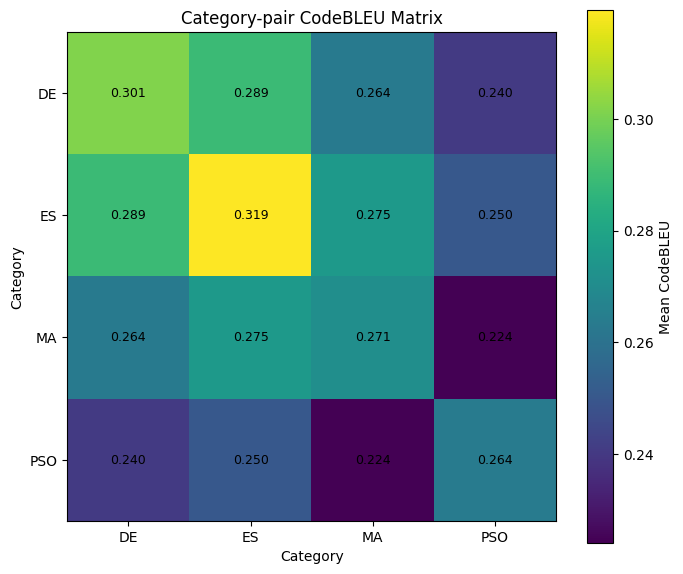

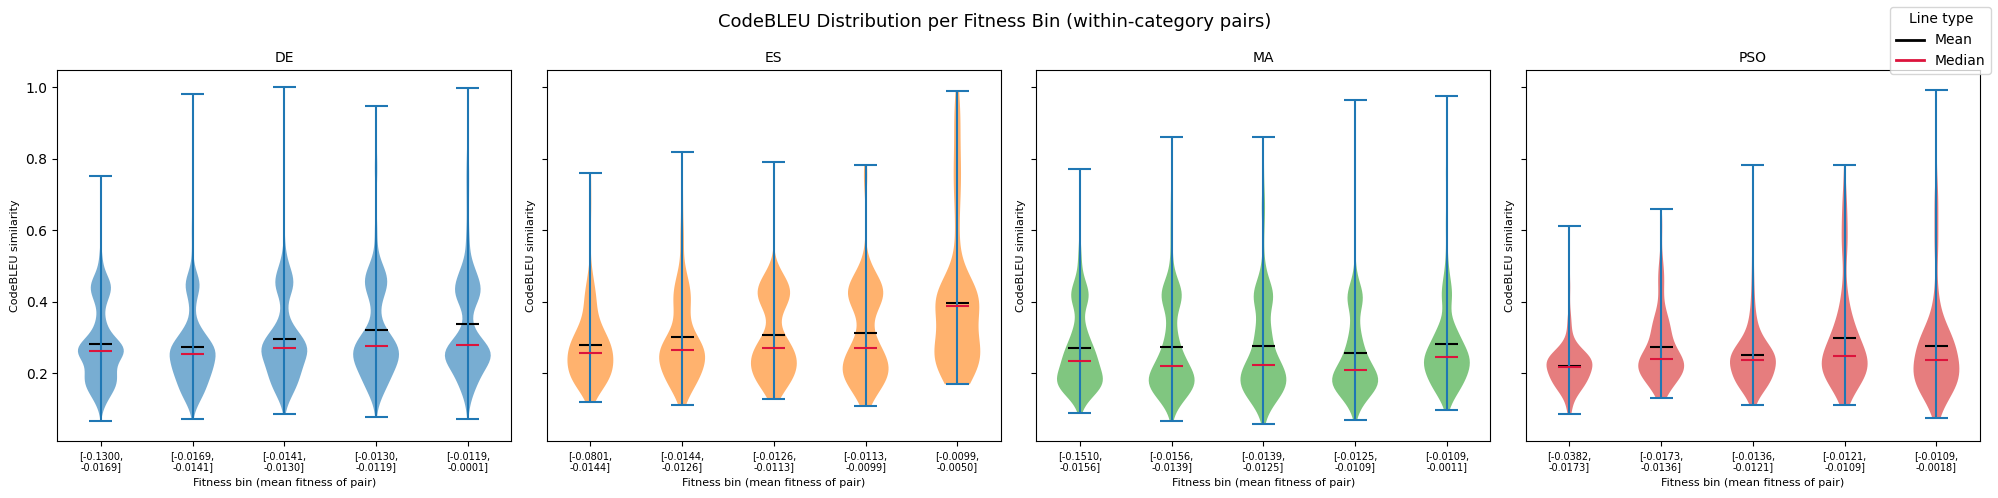

In [11]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from tqdm import tqdm
from itertools import combinations
from scipy.stats import spearmanr
from sklearn.manifold import MDS
from codebleu import calc_codebleu

import logging

FAILURE_THRESHOLD = -1e6
FITNESS_MODE = "max"   # change to "min" for MSE


def compute_codebleu_pair(reference_code, prediction_code):
    reference_code = "" if reference_code is None else str(reference_code)
    prediction_code = "" if prediction_code is None else str(prediction_code)

    if not reference_code.strip() or not prediction_code.strip():
        return np.nan

    try:
        result = calc_codebleu(
            references=[reference_code],
            predictions=[prediction_code],
            lang="python",
            # Data-flow ignored because CodeBLEU warnings showed it was unreliable
            weights=(1/3, 1/3, 0.0, 1/3),
        )

        score = result.get("codebleu", result.get("CodeBLEU"))
        return float(score) if score is not None else np.nan

    except Exception as e:
        print("CodeBLEU failed for one pair:", type(e).__name__, e)
        return np.nan

# compute spearman 
def safe_spearman(x, y):
    """Compute Spearman only when there is enough non-constant data."""
    if len(x) < 4:
        return np.nan, np.nan
    if pd.Series(x).nunique() <= 1 or pd.Series(y).nunique() <= 1:
        return np.nan, np.nan
    return spearmanr(x, y)

print(f"Rows before cleaning: {len(df_plot)}")

bad_fitness = (
    (df_plot["fitness"] < FAILURE_THRESHOLD) |
    (df_plot["fitness"] == -np.inf) |
    (df_plot["fitness"] == np.inf) |
    (df_plot["fitness"].isna())
)

print(f"Rows removed (failed fitness): {bad_fitness.sum()}")

df_clean = df_plot[~bad_fitness].copy().reset_index(drop=True)

df_clean["code"] = df_clean["code"].fillna("").astype(str)
df_clean = df_clean[
    df_clean["code"].str.strip().ne("") &
    df_clean["algorithm_category"].notna() &
    df_clean["name"].notna()
].reset_index(drop=True)

MIN_RUNS = 50
N_FITNESS_BINS = 5  # for stratified sampling

logging.disable(logging.WARNING) # ignore dataflow warning

# drop algorithm names with fewer than 50 runs
run_counts = df_clean.groupby("algorithm_category").size()
valid_categories = run_counts[run_counts >= MIN_RUNS].index
print(f"Categories with >= {MIN_RUNS} runs: {sorted(valid_categories.tolist())}")
print(f"Dropped categories: {sorted(run_counts[run_counts < MIN_RUNS].index.tolist())}")
df_clean = df_clean[df_clean["algorithm_category"].isin(valid_categories)].reset_index(drop=True)

# using a per (name, code) version (unlike above which was only name)
agg_dict = {
    "category":     ("algorithm_category", "first"),  # maps algorithm_category → category
    "best_fitness": ("fitness", "max" if FITNESS_MODE == "max" else "min"),
    "mean_fitness": ("fitness", "mean"),
    "n_runs":       ("fitness", "count"),
}

if "description" in df_clean.columns:
    agg_dict["description"] = ("description", "first")

version_df = (
    df_clean
    .groupby(["name", "code"], as_index=False)
    .agg(**agg_dict)
)

version_df["version_id"] = (
    version_df["name"] + "_v" +
    version_df.groupby("name").cumcount().add(1).astype(str)
)

print(f"\nTotal unique (name, code) versions: {len(version_df)}")
print(version_df["category"].value_counts())

# select the name code versions per algorithm 
# Strategy A: best + worst + median (3 versions per name)
# Strategy B: stratified sample across fitness bins per category

def select_best_worst_median(grp):
    if len(grp) == 1:
        return grp
    if len(grp) == 2:
        return grp
    sorted_grp = grp.sort_values("best_fitness", ascending=False)
    best   = sorted_grp.iloc[[0]]
    worst  = sorted_grp.iloc[[-1]]
    median = sorted_grp.iloc[[len(sorted_grp) // 2]]
    return pd.concat([best, worst, median]).drop_duplicates(subset="version_id")

strategy_a = (
    version_df
    .groupby("name", group_keys=False)
    .apply(select_best_worst_median)
    .reset_index(drop=True)
)
print(f"\nStrategy A (best+worst+median): {len(strategy_a)} versions")
print(strategy_a["category"].value_counts())

def stratified_fitness_sample(grp, n_bins=N_FITNESS_BINS):
    if len(grp) <= n_bins:
        return grp
    try:
        grp = grp.copy()
        grp["_bin"] = pd.qcut(grp["best_fitness"], q=n_bins, duplicates="drop", labels=False)
        return (
            grp.groupby("_bin", group_keys=False)
            .apply(lambda b: b.nlargest(1, "best_fitness"))
            .drop(columns="_bin")
            .reset_index(drop=True)
        )
    except Exception:
        return grp.nlargest(n_bins, "best_fitness")

strategy_b = (
    version_df
    .groupby(["category", "name"], group_keys=False)
    .apply(stratified_fitness_sample)
    .reset_index(drop=True)
)

for col in ["name", "category"]:
    if col not in strategy_b.columns:
        strategy_b = strategy_b.merge(
            version_df[["version_id", col]],
            on="version_id",
            how="left"
        )

print(f"\nStrategy B (stratified across fitness bins): {len(strategy_b)} versions")
print(strategy_b["category"].value_counts())

# merge both strategies, deduplicate
algo_df = (
    pd.concat([strategy_a, strategy_b])
    .drop_duplicates(subset="version_id")
    .reset_index(drop=True)
)

print(f"\nFinal algo_df after combining strategies: {len(algo_df)} versions")
print(algo_df["category"].value_counts())

# Lookups
fitness_lookup  = algo_df.set_index("version_id")["best_fitness"].to_dict()
category_lookup = algo_df.set_index("version_id")["category"].to_dict()
name_lookup     = algo_df.set_index("version_id")["name"].to_dict()
names_all       = algo_df["version_id"].tolist()
categories      = sorted(algo_df["category"].dropna().unique())

def safe_fitness(version_id):
    v = fitness_lookup.get(version_id, np.nan)
    if v is None or pd.isna(v) or v < FAILURE_THRESHOLD:
        return np.nan
    return float(v)

print(f"\nUnique algorithms for CodeBLEU: {len(algo_df)}")
print(algo_df["category"].value_counts())


bad_in_lookup = {k: v for k, v in fitness_lookup.items() if v < FAILURE_THRESHOLD}
print(f"\nSentinel values still in fitness_lookup: {len(bad_in_lookup)}")
for k, v in bad_in_lookup.items():
    print(f"  {k}: {v}")

# Pairwise code bleu

pair_scores_named = []

algo_records = algo_df[["version_id", "name", "code", "category"]].to_dict("records")
total_pairs = len(algo_records) * (len(algo_records) - 1) // 2

for a, b in tqdm(combinations(algo_records, 2), total=total_pairs, desc="CodeBLEU"):
    name_a, code_a, cat_a, vid_a = a["name"], a["code"], a["category"], a["version_id"]
    name_b, code_b, cat_b, vid_b = b["name"], b["code"], b["category"], b["version_id"]

    score = compute_codebleu_pair(code_a, code_b)

    if not np.isnan(score):
        fa = safe_fitness(vid_a)
        fb = safe_fitness(vid_b)

        pair_scores_named.append({
            "pair":         "-".join(sorted([cat_a, cat_b])),
            "cat_a":        cat_a,
            "cat_b":        cat_b,
            "version_id_a": vid_a,
            "version_id_b": vid_b,
            "name_a":       name_a,
            "name_b":       name_b,
            "codebleu":     score,
            "fitness_a":    fa,
            "fitness_b":    fb,
            "fitness_diff": abs(fa - fb) if not (np.isnan(fa) or np.isnan(fb)) else np.nan,
            "fitness_mean": np.nanmean([fa, fb]) if not (np.isnan(fa) and np.isnan(fb)) else np.nan,
            "is_within":    cat_a == cat_b,
        })

psn = pd.DataFrame(pair_scores_named)

print(f"\nTotal scored pairs: {len(psn)}")
print(f"Expected unordered pairs: {total_pairs}")

if not psn.empty:
    print(f"Pairs with NaN fitness_diff: {psn['fitness_diff'].isna().sum()}")
    print(f"fitness_diff range: {psn['fitness_diff'].min():.6f} → {psn['fitness_diff'].max():.6f}")

# category pair codebleu matrix used in paper

matrix = pd.DataFrame(index=categories, columns=categories, dtype=float)

for cat_a in categories:
    for cat_b in categories:
        if cat_a == cat_b:
            sub = psn[
                (psn["cat_a"] == cat_a) &
                (psn["cat_b"] == cat_b)
            ]
        else:
            sub = psn[
                ((psn["cat_a"] == cat_a) & (psn["cat_b"] == cat_b)) |
                ((psn["cat_a"] == cat_b) & (psn["cat_b"] == cat_a))
            ]

        matrix.loc[cat_a, cat_b] = sub["codebleu"].mean()

print("\nCategory-pair CodeBLEU matrix:")
print(matrix)


plt.figure(figsize=(7, 6))
plt.imshow(matrix.astype(float), interpolation="nearest")
plt.colorbar(label="Mean CodeBLEU")
plt.xticks(range(len(categories)), categories)
plt.yticks(range(len(categories)), categories)

for i, cat_a in enumerate(categories):
    for j, cat_b in enumerate(categories):
        value = matrix.loc[cat_a, cat_b]
        if not pd.isna(value):
            plt.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=9)

plt.title("Category-pair CodeBLEU Matrix")
plt.xlabel("Category")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# codebleu similarity vs fitness difference violin plot

within = psn[psn["is_within"]]

between_pairs = [
    (a, b)
    for i, a in enumerate(categories)
    for b in categories[i + 1:]
]

plot_groups = [("Within-category all", within)] + [
    (
        f"{a} vs {b}",
        psn[
            ((psn["cat_a"] == a) & (psn["cat_b"] == b)) |
            ((psn["cat_a"] == b) & (psn["cat_b"] == a))
        ]
    )
    for a, b in between_pairs
]

fitness_vals = np.array([safe_fitness(vid) for vid in names_all])
cat_vals = [category_lookup.get(vid, "Other") for vid in names_all]
unique_cats = sorted(set(cat_vals))
cat_colors = {cat: cm.tab10(i % 10) for i, cat in enumerate(unique_cats)}

N_BINS = 5

fig, axes = plt.subplots(1, len(categories), figsize=(5 * len(categories), 5), sharey=True)

if len(categories) == 1:
    axes = [axes]

for ax, cat in zip(axes, categories):
    # get all within-category pairs for this category
    sub = psn[
        (psn["cat_a"] == cat) &
        (psn["cat_b"] == cat)
    ].dropna(subset=["fitness_mean", "codebleu"])

    if sub.empty:
        ax.set_title(f"{cat}\n(no data)")
        continue

    try:
        sub = sub.copy()
        sub["fitness_bin"] = pd.qcut(
            sub["fitness_mean"],
            q=N_BINS,
            duplicates="drop"
        )

        bin_labels = sub["fitness_bin"].cat.categories
        codebleu_per_bin = [
            sub.loc[sub["fitness_bin"] == b, "codebleu"].values
            for b in bin_labels
        ]
        label_strs = [
            f"[{b.left:.4f},\n{b.right:.4f}]"
            for b in bin_labels
        ]

        vp = ax.violinplot(
            codebleu_per_bin,
            positions=range(len(bin_labels)),
            showmeans=True,
            showmedians=True
        )

        for pc in vp["bodies"]:
            pc.set_facecolor(cat_colors.get(cat, "steelblue"))
            pc.set_alpha(0.6)
        vp["cmeans"].set_color("black")
        vp["cmedians"].set_color("crimson")

        ax.set_xticks(range(len(bin_labels)))
        ax.set_xticklabels(label_strs, fontsize=7)
        ax.set_title(f"{cat}", fontsize=10)
        ax.set_xlabel("Fitness bin (mean fitness of pair)", fontsize=8)
        ax.set_ylabel("CodeBLEU similarity", fontsize=8)

    except Exception as e:
        ax.set_title(f"{cat}\nError: {e}")

# shared legend
mean_line   = plt.Line2D([], [], color="black",  linewidth=2, label="Mean")
median_line = plt.Line2D([], [], color="crimson", linewidth=2, label="Median")
fig.legend(handles=[mean_line, median_line], loc="upper right", title="Line type")

plt.suptitle("CodeBLEU Distribution per Fitness Bin (within-category pairs)", fontsize=13)
plt.tight_layout()
plt.show()

# summary table, mean CodeBLEU per bin per category
# print("\n── Mean CodeBLEU per fitness bin ──")
# for cat in categories:
#     sub = psn[
#         (psn["cat_a"] == cat) &
#         (psn["cat_b"] == cat)
#     ].dropna(subset=["fitness_mean", "codebleu"])

#     if sub.empty:
#         continue

#     try:
#         sub = sub.copy()
#         sub["fitness_bin"] = pd.qcut(sub["fitness_mean"], q=N_BINS, duplicates="drop")
#         print(f"\n{cat}:")
#         print(
#             sub.groupby("fitness_bin", observed=True)["codebleu"]
#             .agg(["mean", "std", "count"])
#             .rename(columns={"mean": "mean_codebleu", "std": "std_codebleu", "count": "n_pairs"})
#             .to_string()
#         )
#     except Exception as e:
#         print(f"{cat}: Error — {e}")

# # CORRELATION SUMMARY
# print("\n── Correlation summary: mean within-category CodeBLEU vs best fitness ──")
# print(f"{'Category':<8} {'N':>4} {'Spearman ρ':>12} {'p-value':>10}")



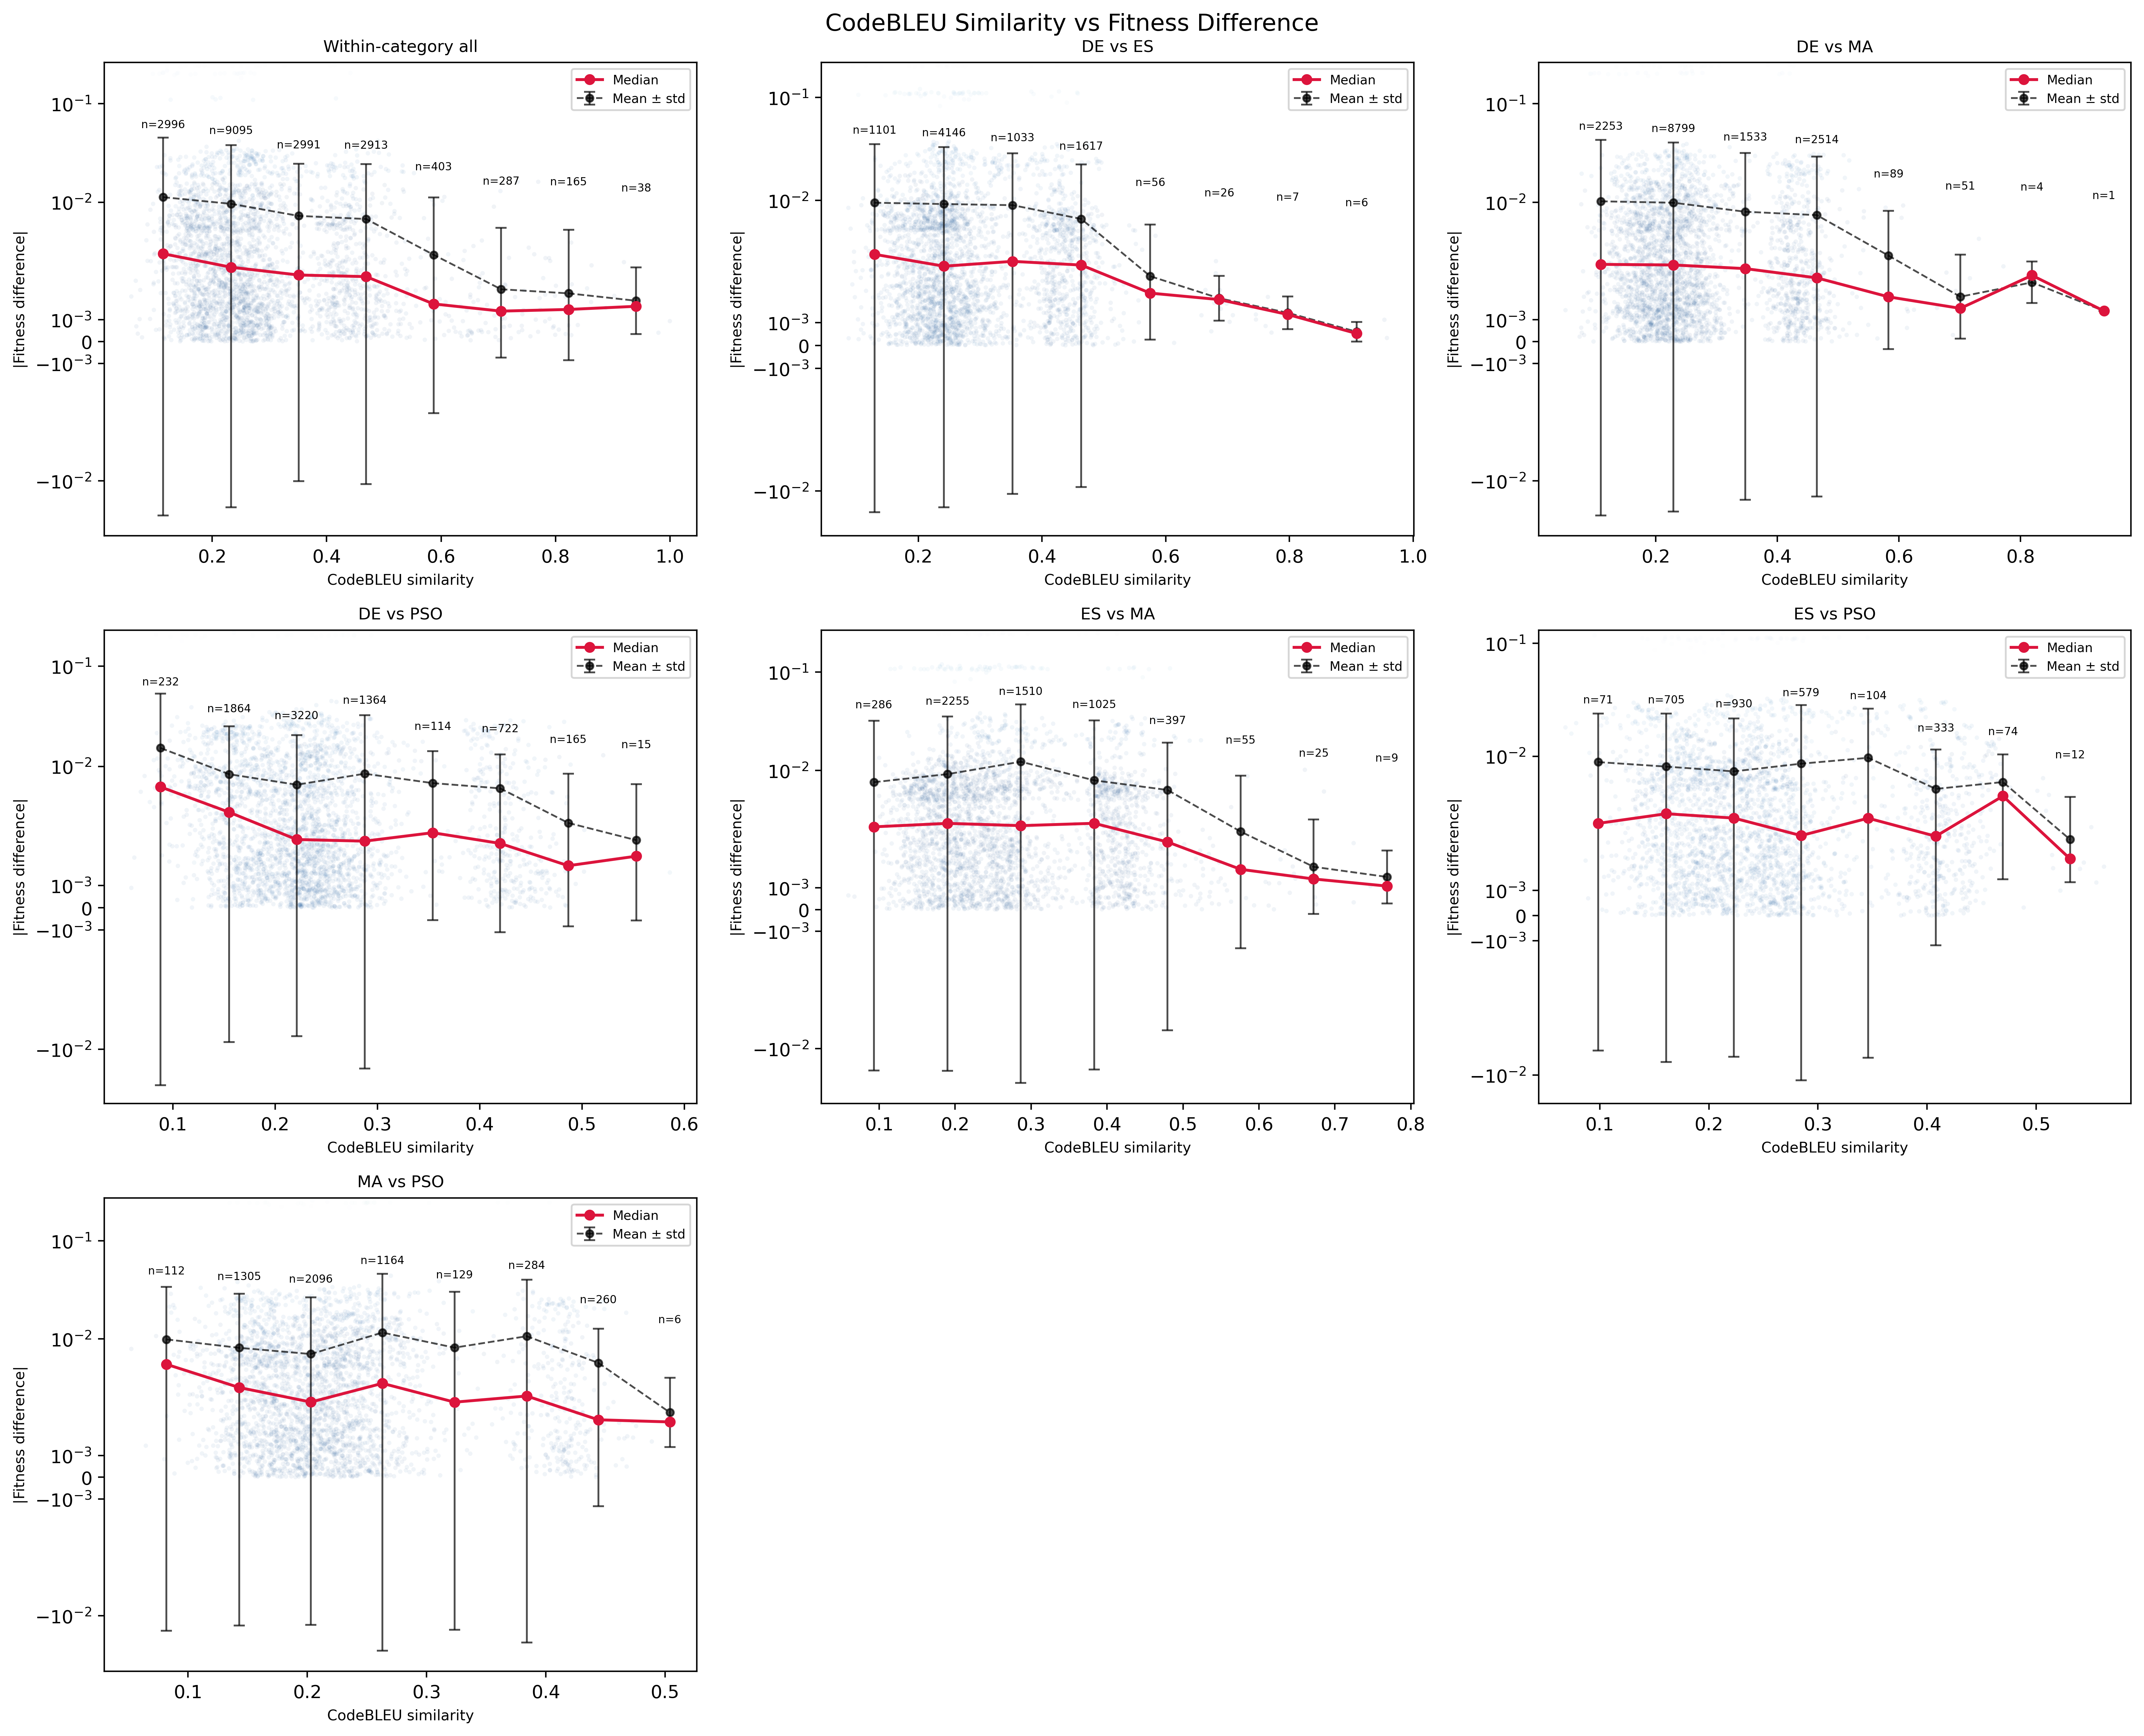

In [12]:
N_CODEBLEU_BINS = 8
MAX_PAIRS_PER_PANEL = 3000  # 3000 is to show density of points
Y_LINTHRESH = 0.005          

n_plots = len(plot_groups)
ncols = 3
nrows = math.ceil(n_plots / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows), dpi=400)
axes = np.array(axes).flatten()

for ax, (label, sub) in zip(axes, plot_groups):
    sub = sub.dropna(subset=["fitness_diff", "codebleu", "fitness_mean"])

    if sub.empty:
        ax.set_visible(False)
        continue

    try:
        sub = sub.copy()
        sub["codebleu_bin"] = pd.cut(
            sub["codebleu"],
            bins=N_CODEBLEU_BINS,
            include_lowest=True
        )

        binned = (
            sub.groupby("codebleu_bin", observed=True)["fitness_diff"]
            .agg(["mean", "median", "std", "count"])
            .reset_index()
        )
        binned["bin_mid"] = binned["codebleu_bin"].apply(lambda b: b.mid)
        binned["std"] = binned["std"].fillna(0)

        # plot the raw points to see density 
        sample = sub.sample(min(MAX_PAIRS_PER_PANEL, len(sub)), random_state=42)
        ax.scatter(
            sample["codebleu"],
            sample["fitness_diff"],
            alpha=0.06,
            s=6,
            c=sample["fitness_mean"],
            cmap="Blues",
            edgecolors="none",
            zorder=1
        )

        # median line 
        ax.plot(
            binned["bin_mid"],
            binned["median"],
            "o-",
            color="crimson",
            linewidth=1.6,
            markersize=5,
            zorder=3,
            label="Median"
        )

        # mean ± std, used as well for visual comparison 
        ax.errorbar(
            binned["bin_mid"],
            binned["mean"],
            yerr=binned["std"],
            fmt="o--",
            color="black",
            linewidth=1.0,
            markersize=4,
            capsize=3,
            alpha=0.7,
            zorder=2,
            label="Mean ± std"
        )

        y_min, y_max = ax.get_ylim()
        y_offset = 0.03 * (y_max - y_min)

        for _, row in binned.iterrows():
            ax.annotate(
                f"n={int(row['count'])}",
                (row["bin_mid"], row["mean"] + row["std"] + y_offset),
                fontsize=6,
                ha="center",
                va="bottom",
                color="black",
                zorder=4
            )

    except Exception as e:
        ax.set_title(f"{label}\nBinning error: {e}", fontsize=8)
        continue

    rho, pval = safe_spearman(sub["codebleu"], sub["fitness_diff"])

    if np.isnan(rho):
        ax.set_title(f"{label}\nNot enough variation", fontsize=9)
    else:
        ax.set_title(f"{label}", fontsize=9)

    ax.set_yscale("symlog", linthresh=Y_LINTHRESH)
    ax.set_xlabel("CodeBLEU similarity", fontsize=8)
    ax.set_ylabel("|Fitness difference|", fontsize=8)
    ax.legend(fontsize=7)

for ax in axes[len(plot_groups):]:
    ax.set_visible(False)

plt.suptitle("CodeBLEU Similarity vs Fitness Difference", fontsize=13)
plt.tight_layout()
plt.show()